In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import Data

In [2]:
df_master = pd.read_csv('E:\\Dibimbing\\Assignment Mini Project Data Preprocessing\\Caffe Sales.csv')
df_before = df_master.copy()
df = df_master.copy()
df.head()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


**Deskripsi Dataset**

Dataset (Caffe Sales.csv) ini berisi informasi tentang transaksi dari sebuah kafe, yang berisi kolom sebagai berikut:
- Transaction ID: Kode unik untuk setiap transaksi
- Item: Produk yang dibeli
- Quantity: Jumlah unit yang dibeli
- Price Per Unit: Harga untuk satu unit produk
- Total Spent: Total pengeluaran untuk transaksi tersebut
- Payment Method: Cara pelanggan membayar
- Location: Apakah pesanan untuk dibawa pulang (takeaway) atau makan di tempat (in-store)
- Transaction Date: Tanggal transaksi

In [3]:
print(f" Dimensi Dataset : {df.shape[0]:,} rows × {df.shape[1]} columns")

 Dimensi Dataset : 10,000 rows × 8 columns


In [4]:
print(f" Columns : {list(df.columns)}")

 Columns : ['Transaction ID', 'Item', 'Quantity', 'Price Per Unit', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date']


# Data Exploration

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 3   Price Per Unit    9821 non-null   str  
 4   Total Spent       9827 non-null   str  
 5   Payment Method    7421 non-null   str  
 6   Location          6735 non-null   str  
 7   Transaction Date  9841 non-null   str  
dtypes: str(8)
memory usage: 1.1 MB


In [6]:
print('Jumlah duplikat data :', df.duplicated().sum())

Jumlah duplikat data : 0


In [7]:
for i in df:
    print()
    print(i)
    print(df[i].unique())


Transaction ID
<ArrowStringArray>
['TXN_1961373', 'TXN_4977031', 'TXN_4271903', 'TXN_7034554', 'TXN_3160411',
 'TXN_2602893', 'TXN_4433211', 'TXN_6699534', 'TXN_4717867', 'TXN_2064365',
 ...
 'TXN_1538510', 'TXN_3897619', 'TXN_2739140', 'TXN_4766549', 'TXN_7851634',
 'TXN_7672686', 'TXN_9659401', 'TXN_5255387', 'TXN_7695629', 'TXN_6170729']
Length: 10000, dtype: str

Item
<ArrowStringArray>
[  'Coffee',     'Cake',   'Cookie',    'Salad', 'Smoothie',  'UNKNOWN',
 'Sandwich',        nan,    'ERROR',    'Juice',      'Tea']
Length: 11, dtype: str

Quantity
<ArrowStringArray>
['2', '4', '5', '3', '1', 'ERROR', 'UNKNOWN', nan]
Length: 8, dtype: str

Price Per Unit
<ArrowStringArray>
['2.0', '3.0', '1.0', '5.0', '4.0', '1.5', nan, 'ERROR', 'UNKNOWN']
Length: 9, dtype: str

Total Spent
<ArrowStringArray>
[    '4.0',    '12.0',   'ERROR',    '10.0',    '20.0',     '9.0',    '16.0',
    '15.0',    '25.0',     '8.0',     '5.0',     '3.0',     '6.0',       nan,
 'UNKNOWN',     '2.0',     '1.0',

Hasil pengecekan diatas menunjukkan adanya anomali data berupa nilai 'UNKNOWN' dan 'ERROR'. Karena nilai-nilai tersebut memiliki makna sama dengan Missing Value, bilai tersebut akan diganti dengan NaN untuk mempermudah tahap penanganan missing values.

In [8]:
df = df.replace(['UNKNOWN', 'ERROR'], pd.NA)

In [9]:
(df.isnull().sum()).to_frame(name='Jumlah Missing Value')

,Jumlah Missing Value
Transaction ID,0
Item,969
Quantity,479
Price Per Unit,533
Total Spent,502
Payment Method,3178
Location,3961
Transaction Date,460


In [10]:
((df.isnull().sum()/len(df))*100).to_frame(name='Persentase Missing Value')

,Persentase Missing Value
Transaction ID,0.00
Item,9.69
Quantity,4.79
Price Per Unit,5.33
Total Spent,5.02
Payment Method,31.78
Location,39.61
Transaction Date,4.60


In [11]:
df.dtypes

Transaction ID      str
Item                str
Quantity            str
Price Per Unit      str
Total Spent         str
Payment Method      str
Location            str
Transaction Date    str
dtype: object

In [12]:
df.describe()

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9031,9521,9467,9498,6822,6039,9540
unique,10000,8,5,6,17,3,2,365
top,TXN_1961373,Juice,5,3.0,6.0,Digital Wallet,Takeaway,2023-02-06
freq,1,1171,2013,2429,979,2291,3022,40


**Data Duplicated**

Tidak ditemukan duplikasi data pada dataset sehingga tidak perlu adanya penanganan pada data duplicated.

**Missing Value**

* Transaction ID (0% Missing Value)
* Item (9,69% Missing Value)
* Quantity (4,79% Missing Value)
* Price Per Unit (5,33% Missing Value)
* Total Spent (5,02% Missing Value)
* Payment Method (31.78% Missing Value)
* Location (39,61% Missing Value)
* Transaction Date (4,6% Missing Value)

**Penyesuaian Tipe Data**

Seluruh kolom masih dalam tipe data string. Agar data dapat dianalisis dengan tepat, perlu dilakukan konversi:

* Format Numerik : Quantity, Price Per Unit, dan Total Spent
* Format Datetime: Transaction Date

**Statistik Deskripsif**

Karena seluruh kolom masih berformat string, fungsi df.describe() belum dapat memberikan ringkasan statistik yang bermakna. Analisis deskriptif akan dilakukan setelah tahap konversi tipe data selesai.


**Rencana Tindakan Pembersihan Data**

1. Konversi Tipe Data
2. Penanganan Missing Values
4. Validasi Hasil Cleaning Data

# Data Cleaning: Konversi Tipe Data

Mengidentifikasi tipe data dan inkonsistensi pada data teks, seperti kapitalisasi, spasi, atau penulisan kategori

In [13]:
df.columns = df.columns.str.replace(' ', '_').str.strip()
df.columns

Index(['Transaction_ID', 'Item', 'Quantity', 'Price_Per_Unit', 'Total_Spent',
       'Payment_Method', 'Location', 'Transaction_Date'],
      dtype='str')

In [14]:
df['Transaction_Date'] = pd.to_datetime(df['Transaction_Date'])
df['Quantity'] = pd.to_numeric(df['Quantity'])
df['Price_Per_Unit'] = pd.to_numeric(df['Price_Per_Unit'])
df['Total_Spent'] = pd.to_numeric(df['Total_Spent'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction_ID    10000 non-null  str           
 1   Item              9031 non-null   str           
 2   Quantity          9521 non-null   float64       
 3   Price_Per_Unit    9467 non-null   float64       
 4   Total_Spent       9498 non-null   float64       
 5   Payment_Method    6822 non-null   str           
 6   Location          6039 non-null   str           
 7   Transaction_Date  9540 non-null   datetime64[us]
dtypes: datetime64[us](1), float64(3), str(4)
memory usage: 897.5 KB


# Data Cleaning: Penanganan Missing Values

Pendekatan paling ideal adalah mengevaluasi apakah data tersebut masih bisa diselamatkan. Ketiga kolom numerik dalam dataset ini memiliki relasi matematis:

> **Total Spent = Quantity × Price Per Unit**

Jika dua dari variabel di atas diketahui, nilai yang kosong dapat dihitung. Relasi ini akan kita manfaatkan terlebih dahulu sebelum menggunakan metode imputasi statistik.

In [15]:
harga_per_items = df.groupby('Item')['Price_Per_Unit'].median()
harga_per_items.head(8)

Item
Cake        3.0
Coffee      2.0
Cookie      1.0
Juice       3.0
Salad       5.0
Sandwich    4.0
Smoothie    4.0
Tea         1.5
Name: Price_Per_Unit, dtype: float64

In [16]:
pasangan_harga_item = (
    df.dropna(subset=['Item', 'Price_Per_Unit'])
      .groupby('Price_Per_Unit')['Item']
      .nunique()
)
pasangan_harga_item.head(8)

Price_Per_Unit
1.0    1
1.5    1
2.0    1
3.0    2
4.0    2
5.0    1
Name: Item, dtype: int64

In [17]:
pasangan_yang_unik = pasangan_harga_item[pasangan_harga_item == 1].index
mapping_harga_item = (
    df[df['Price_Per_Unit'].isin(pasangan_yang_unik)]
      .dropna(subset=['Item', 'Price_Per_Unit'])
      .drop_duplicates('Price_Per_Unit')
      .set_index('Price_Per_Unit')['Item']
)
mapping_harga_item.head()

Price_Per_Unit
2.0    Coffee
1.0    Cookie
5.0     Salad
1.5       Tea
Name: Item, dtype: str

In [18]:
persen_missing_sebelum = (df['Item'].isnull().sum() / len(df)) * 100
# Mapping
df['Item'] = df['Item'].fillna(
    df['Price_Per_Unit'].map(mapping_harga_item)
)
missing_sesudah = df['Item'].isna().sum()
persen_missing_sesudah = (missing_sesudah / len(df)) * 100
print("Missing sebelum mapping :", persen_missing_sebelum, "%")
print("Missing sesudah mapping :", persen_missing_sesudah, "%")

Missing sebelum mapping : 9.69 %
Missing sesudah mapping : 5.01 %


In [19]:
harga_tidak_unik = pasangan_harga_item[pasangan_harga_item > 1]
print("Harga yang tidak unik:")
harga_tidak_unik.head()

Harga yang tidak unik:


Price_Per_Unit
3.0    2
4.0    2
Name: Item, dtype: int64

In [20]:
df['Item'] = df['Item'].fillna(df['Item'].mode()[0])

In [21]:
((df.isnull().sum()/len(df))*100).to_frame(name='Persentase Missing Value')

,Persentase Missing Value
Transaction_ID,0.00
Item,0.00
Quantity,4.79
Price_Per_Unit,5.33
Total_Spent,5.02
Payment_Method,31.78
Location,39.61
Transaction_Date,4.60


Strategi Pemulihan Data Kolom Item

- Karena harga setiap barang bersifat tetap, nilai Item yang hilang dipulihkan dengan mencocokkannya (mapping) terhadap kolom Price Per Unit.

- Proses ini tidak mencakup keseluruhan data karena terdapat harga yang tumpang tindih (overlap). Harga 3.0 dan 4.0 masing-masing dimiliki oleh dua barang yang berbeda, sehingga memunculkan ambiguitas yang tidak dapat diselesaikan secara logis.

- Hasil Pemetaan ini berhasil menurunkan persentase missing values secara signifikan dari 9,69% menjadi 5,01%. Sisa kekosongan akibat 4 item yang ambigu tersebut akan dihapus/drop baris karena presentasi missing nya bernilai 5% yang aman untuk hapus demi data yang logis.

In [22]:
mapping_item_harga = (
    df.dropna(subset=['Item', 'Price_Per_Unit'])
      .groupby('Item')['Price_Per_Unit']
      .median()
)
df['Price_Per_Unit'] = df['Price_Per_Unit'].fillna(df['Item'].map(mapping_item_harga))
((df.isnull().sum()/len(df))*100).to_frame(name='Persentase Missing Value')

,Persentase Missing Value
Transaction_ID,0.00
Item,0.00
Quantity,4.79
Price_Per_Unit,0.00
Total_Spent,5.02
Payment_Method,31.78
Location,39.61
Transaction_Date,4.60


Missing values pada kolom Price_Per_Unit ditangani dengan cara mengimputasi kecocokan nilai median harga berdasarkan kategori Item. Pendekatan ini dipilih karena data numerik yang lebih tahan terhadap pengaruh outliers jika menggunakan median. Hasilnya seluruh kekosongan data telah teratasi sehingga persentase missing values berhasil mencapai angka 0%.

In [23]:
df['Quantity'] = df['Quantity'].fillna(df['Total_Spent']/df['Price_Per_Unit'])
df['Quantity'] = df['Quantity'].round().astype('Int64')
((df.isnull().sum()/len(df))*100).to_frame(name='Persentase Missing Value')

,Persentase Missing Value
Transaction_ID,0.00
Item,0.00
Quantity,0.20
Price_Per_Unit,0.00
Total_Spent,5.02
Payment_Method,31.78
Location,39.61
Transaction_Date,4.60


Missing values pada kolom Quantity dipulihkan secara matematis dengan membagi nilai Total_Spent dengan Price_Per_Unit. Dikarenakan Quantity barang yang dijual di kafe harusnya berupa angka bulat, hasil kalkulasi tersebut kemudian dikonversi menjadi tipe data Int64 agar relevan dengan logika bisnis dunia nyata.

In [24]:
df['Total_Spent'] = df['Total_Spent'].fillna(df['Quantity'] * df['Price_Per_Unit'])
((df.isnull().sum()/len(df))*100).to_frame(name='Persentase Missing Value')

,Persentase Missing Value
Transaction_ID,0.00
Item,0.00
Quantity,0.20
Price_Per_Unit,0.00
Total_Spent,0.20
Payment_Method,31.78
Location,39.61
Transaction_Date,4.60


In [25]:
df[df['Total_Spent'].isnull()]

,Transaction_ID,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Location,Transaction_Date
236,TXN_8562645,Salad,<NA>,5.0,<NA>,NaN,In-store,2023-05-18
278,TXN_3229409,Juice,<NA>,3.0,<NA>,Cash,Takeaway,2023-04-15
641,TXN_2962976,Juice,<NA>,3.0,<NA>,NaN,NaN,2023-03-17
738,TXN_8696094,Sandwich,<NA>,4.0,<NA>,NaN,Takeaway,2023-05-14
2796,TXN_9188692,Cake,<NA>,3.0,<NA>,Credit Card,NaN,2023-12-01
3203,TXN_4565754,Smoothie,<NA>,4.0,<NA>,Digital Wallet,Takeaway,2023-10-06
3224,TXN_6297232,Coffee,<NA>,2.0,<NA>,NaN,NaN,2023-04-07
3401,TXN_3251829,Tea,<NA>,1.5,<NA>,Digital Wallet,In-store,2023-07-25
4257,TXN_6470865,Coffee,<NA>,2.0,<NA>,Digital Wallet,Takeaway,2023-09-18
5841,TXN_5884081,Cookie,<NA>,1.0,<NA>,Digital Wallet,In-store,2023-07-05


In [26]:
df = df.dropna(subset=['Total_Spent'])
((df.isnull().sum()/len(df))*100).to_frame(name='Persentase Missing Value')

,Persentase Missing Value
Transaction_ID,0.000000
Item,0.000000
Quantity,0.000000
Price_Per_Unit,0.000000
Total_Spent,0.000000
Payment_Method,31.773547
Location,39.629259
Transaction_Date,4.609218


Untuk mengatasi missing value pada kolom Total_Spent, kami menggunakan hasil kali antara Quantity dan Price_Per_Unit. Cara ini sangat efektif dan mampu menekan angka data kosong dari 5% hingga tersisa 0,20% saja. Sisa data tersebut tidak dapat kami hitung karena ada dua kolom yang nilainya kosong secara bersamaan. Karena porsinya sangat kecil dan berada di bawah 5%, baris data tersebut akhirnya kami hapus agar tidak mengganggu analisis.

In [27]:
# Penanganan missing values pada kolom Payment Method
df['Payment_Method'] = df['Payment_Method'].fillna('Not Specified')
df['Payment_Method'].unique()

<ArrowStringArray>
['Credit Card', 'Cash', 'Not Specified', 'Digital Wallet']
Length: 4, dtype: str

In [28]:
# Penanganan missing values pada kolom Location
df['Location'] = df['Location'].fillna('Not Specified')
df['Location'].unique()

<ArrowStringArray>
['Takeaway', 'In-store', 'Not Specified']
Length: 3, dtype: str

In [29]:
((df.isnull().sum()/len(df))*100).to_frame(name='Persentase Missing Value')

,Persentase Missing Value
Transaction_ID,0.000000
Item,0.000000
Quantity,0.000000
Price_Per_Unit,0.000000
Total_Spent,0.000000
Payment_Method,0.000000
Location,0.000000
Transaction_Date,4.609218


Karena persentase data kosong pada kolom Payment Method dan Location tinggi, Diputuskan untuk mengimputasinya dengan label khusus. hal ini karena ada dugaan ketiadaan data pembayaran disebabkan oleh sistem yang belum mendukung metode pembayaran digital terbaru pelanggan, sedangkan data lokasi hilang karena adanya opsi di luar In-store dan Takeaway (seperti Delivery atau Drive-thru). Label ini sekaligus berfungsi sebagai penanda anomali yang memerlukan investigasi lapangan.

In [30]:
df['Transaction_Date'] = df['Transaction_Date'].ffill()
((df.isnull().sum()/len(df))*100).to_frame(name='Persentase Missing Value')

,Persentase Missing Value
Transaction_ID,0.0
Item,0.0
Quantity,0.0
Price_Per_Unit,0.0
Total_Spent,0.0
Payment_Method,0.0
Location,0.0
Transaction_Date,0.0


# Data Cleaning: Deteksi Outliers

Mengidentifikasi outlier menggunakan metode yang sesuai

In [31]:
# Data Numerik
q1 = df['Quantity'].quantile(0.25)
q3 = df['Quantity'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
print('Jumlah Outlier pada kolom Quantity adalah',len(df[(df['Quantity'] < lower_bound) | (df['Quantity'] > upper_bound)]))

Jumlah Outlier pada kolom Quantity adalah 2


In [32]:
q1 = df['Total_Spent'].quantile(0.25)
q3 = df['Total_Spent'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
print('Jumlah Outlier pada kolom Total Spent adalah',len(df[(df['Total_Spent'] < lower_bound) | (df['Total_Spent'] > upper_bound)]))

Jumlah Outlier pada kolom Total Spent adalah 269


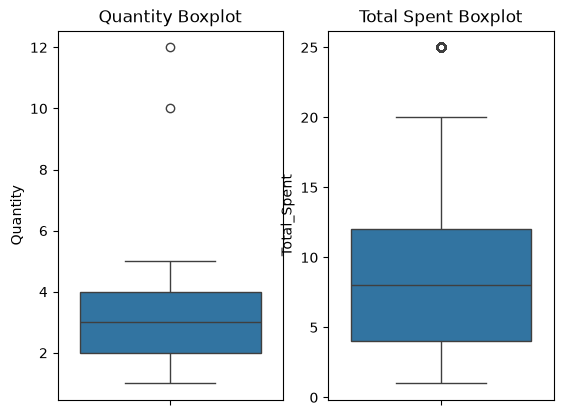

In [33]:
plt.subplot(1, 2, 1)
sns.boxplot(y=df['Quantity'])
plt.title('Quantity Boxplot')
plt.subplot(1, 2, 2)
sns.boxplot(y=df['Total_Spent'])
plt.title('Total Spent Boxplot')
plt.show()

Metode Penanganan Outlier: Perhatankan

Berdasarkan metode IQR, ditemukan 2 outlier pada kolom Quantity dan 269 outlier pada kolom Total_Spent. Setelah memperhatiakan pola di dunia nyata, outlier tersebut akan dipertahankan karena merupakan natural outliers dari pembelian menu yang merepresentasikan transaksi nyata dan krusial untuk analisis performa penjualan.

# Encoding Data Katagorikal

In [34]:
df_encoded = pd.get_dummies(
    df, 
    columns=['Item', 'Payment_Method', 'Location'], 
    drop_first=True,
    dtype=int
)
df_encoded.head()

,Transaction_ID,Quantity,Price_Per_Unit,Total_Spent,Transaction_Date,Item_Coffee,Item_Cookie,Item_Juice,Item_Salad,Item_Sandwich,Item_Smoothie,Item_Tea,Payment_Method_Credit Card,Payment_Method_Digital Wallet,Payment_Method_Not Specified,Location_Not Specified,Location_Takeaway
0,TXN_1961373,2,2.0,4.0,2023-09-08,1,0,0,0,0,0,0,1,0,0,0,1
1,TXN_4977031,4,3.0,12.0,2023-05-16,0,0,0,0,0,0,0,0,0,0,0,0
2,TXN_4271903,4,1.0,4.0,2023-07-19,0,1,0,0,0,0,0,1,0,0,0,0
3,TXN_7034554,2,5.0,10.0,2023-04-27,0,0,0,1,0,0,0,0,0,1,1,0
4,TXN_3160411,2,2.0,4.0,2023-06-11,1,0,0,0,0,0,0,0,1,0,0,0


Metode encoding yang digunakan adalah One-Hot Encoding pada kolom kategorik (Item, Payment_Method, dan Location) menggunakan pd.get_dummies(). Kolom Transaction_ID sengaja tidak diencoding karena penanda data unik. Hasil Encoding disimpan dalam dataframe baru untuk analisis korelasi numerik (heatmap) atau machine learning dan menjaga dataframe asli tetap utuh untuk kebutuhan visualisasi EDA.

# Feature Engineering

In [35]:
df['Month']       = df['Transaction_Date'].dt.month
df['Month_Name']  = df['Transaction_Date'].dt.strftime('%b')
df['Day_Name'] = df['Transaction_Date'].dt.day_name()
df['Quarter']     = df['Transaction_Date'].dt.quarter
df.head()

,Transaction_ID,Item,Quantity,Price_Per_Unit,Total_Spent,Payment_Method,Location,Transaction_Date,Month,Month_Name,Day_Name,Quarter
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08,9,Sep,Friday,3
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16,5,May,Tuesday,2
2,TXN_4271903,Cookie,4,1.0,4.0,Credit Card,In-store,2023-07-19,7,Jul,Wednesday,3
3,TXN_7034554,Salad,2,5.0,10.0,Not Specified,Not Specified,2023-04-27,4,Apr,Thursday,2
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11,6,Jun,Sunday,2


# Validasi Hasil Cleaning

In [36]:
print(f'Dimensi Dataset Bersih : {df.shape[0]:,} baris × {df.shape[1]} kolom')
print()
validation = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Dtype': df.dtypes.astype(str)
})
validation

Dimensi Dataset Bersih : 9,980 baris × 12 kolom



,Missing Values,Dtype
Transaction_ID,0,str
Item,0,str
Quantity,0,Int64
Price_Per_Unit,0,float64
Total_Spent,0,Float64
Payment_Method,0,str
Location,0,str
Transaction_Date,0,datetime64[us]
Month,0,int32
Month_Name,0,str


# Exploratory Data Analysis (EDA)

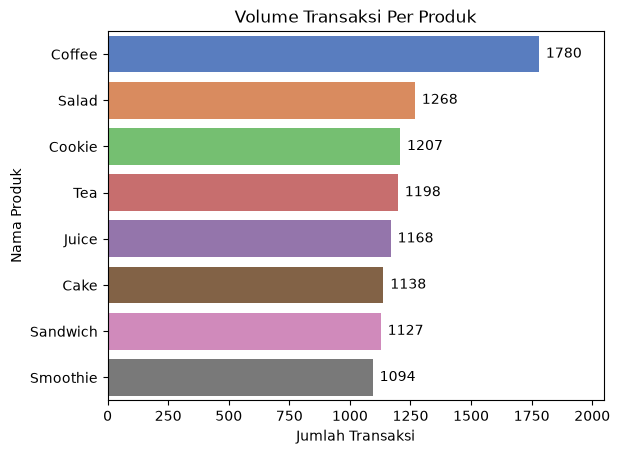

In [37]:
# Produk Terlaris berdasarkan Volume Transaksi
item_counts = df['Item'].value_counts().reset_index()
item_counts.columns = ['Item', 'Frekuensi Pesanan']
produk_terlaris = sns.barplot(
    data=item_counts, 
    x='Frekuensi Pesanan', 
    y='Item', 
    hue='Item',
    palette='muted',
)
plt.title('Volume Transaksi Per Produk')
plt.xlabel('Jumlah Transaksi')
plt.ylabel('Nama Produk')
for p in produk_terlaris.containers:
    produk_terlaris.bar_label(p, padding=5, fmt='%.0f')
produk_terlaris.set_xlim(0, item_counts['Frekuensi Pesanan'].max() * 1.15)
plt.show()

**Insight:**
- Coffee adalah produk terlaris dengan 1.777 transaksi, disusul Salad dan Cookie. Produk lainnya yang cenderung tersebar merata.
- Coffee berperan sebagai produk yang menarik trafik pelanggan. Manajemen perlu memastikan ketersediaan biji kopi dan konsistensi rasa agar trafik harian pelanggan tetap terjaga.

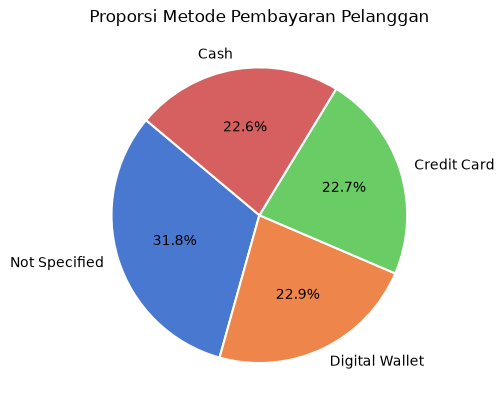

In [38]:
# Proporsi Metode Pembayaran
payment_counts = df['Payment_Method'].value_counts()
colors = sns.color_palette('muted')
plt.pie(
    payment_counts, 
    labels=payment_counts.index, 
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.title('Proporsi Metode Pembayaran Pelanggan')
plt.show()

**Insight:**
- Terdapat 31,76% transaksi tidak tercatat (Not Specified). Dari transaksi yang tercatat, preferensi pembayaran sangat seimbang: Digital Wallet (22,90%), Credit Card (22,74%), dan Cash (22,59%).
- Hal ini menunjukkan adanya celah pencatatan pada sistem yang perlu segera diperbaiki.

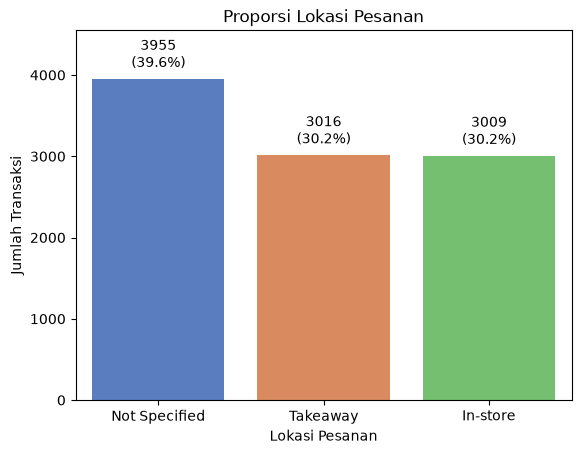

In [39]:
# Proporsi Lokasi (In-store vs Takeaway)
location_counts = df['Location'].value_counts().reset_index()
location_counts.columns = ['Location', 'Jumlah Transaksi']
total_transactions = location_counts['Jumlah Transaksi'].sum()
ax = sns.barplot(
    data=location_counts, 
    x='Location', 
    y='Jumlah Transaksi', 
    hue='Location', 
    palette='muted', 
    legend=False
)
plt.title('Proporsi Lokasi Pesanan')
plt.xlabel('Lokasi Pesanan')
plt.ylabel('Jumlah Transaksi')
# tampilkan nilai dan persentase
for p in ax.patches:
    height = p.get_height()
    percentage = f'{(height/total_transactions)*100:.1f}%'
    ax.annotate(f'{int(height)}\n({percentage})', 
                xy=(p.get_x() + p.get_width() / 2, height),
                xytext=(0, 5),
                textcoords="offset points",
                ha='center', va='bottom')
plt.ylim(0, location_counts['Jumlah Transaksi'].max() * 1.15)
plt.show()

**Insight:**
- Temuan Utama: Sebanyak 39,62% lokasi tidak tercatat. Dari transaksi valid, porsi Takeaway (30,23%) dan In-store (30,15%) seimbang sempurna (50:50).
- Hal ini menunjukkan adanya celah pencatatan pada sistem yang perlu segera diperbaiki

In [40]:
df['Total_Spent'].describe()

count      9980.0
mean     8.929459
std      6.004235
min           1.0
25%           4.0
50%           8.0
75%          12.0
max          25.0
Name: Total_Spent, dtype: Float64

**Insight:**
- Rata-rata pengeluaran adalah $8,93 dengan median $8,00 (rentang $1–$25). Sebanyak Q3 transaksi bernilai $12,00.
- Untuk menaikkan Average Order Value (AOV) melewati batas $12, kafe dapat menerapkan strategi upselling (contoh: tambah topping/upsize) dan cross-selling camilan di kasir.

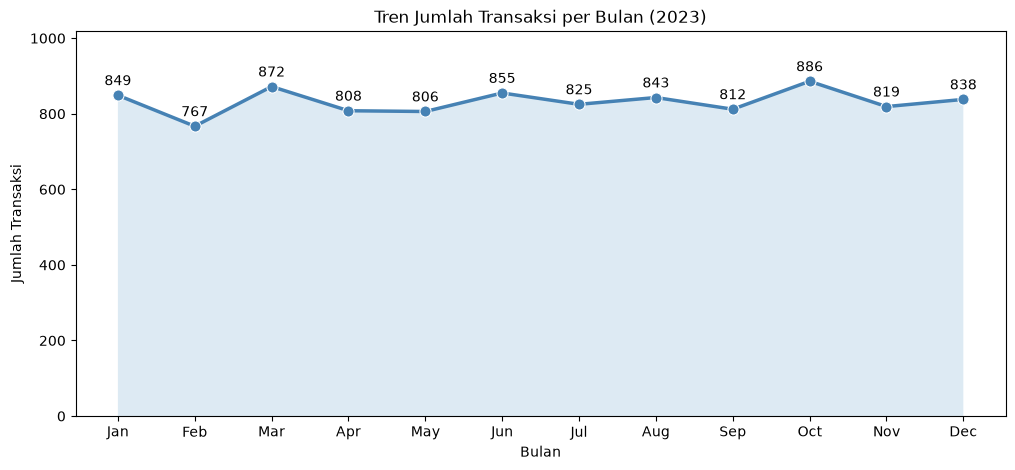

In [41]:
# Tren Jumlah Transaksi per Bulan
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_txn = (
    df.groupby('Month_Name')['Transaction_ID']
      .count()
      .reindex(month_order)
      .reset_index()
)
monthly_txn.columns = ['Bulan', 'Jumlah Transaksi']

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(
    data=monthly_txn, 
    x='Bulan', 
    y='Jumlah Transaksi',
    marker='o', 
    color='steelblue', 
    linewidth=2.5, 
    markersize=8,
    ax=ax
)
ax.fill_between(
    monthly_txn['Bulan'], 
    monthly_txn['Jumlah Transaksi'],
    alpha=0.15, 
)
offset = monthly_txn['Jumlah Transaksi'].max() * 0.03 
for i, row in monthly_txn.iterrows():
    ax.text(i, row['Jumlah Transaksi'] + offset, f"{row['Jumlah Transaksi']:,}",
            ha='center')
ax.set_title('Tren Jumlah Transaksi per Bulan (2023)')
ax.set_xlabel('Bulan')
ax.set_ylabel('Jumlah Transaksi')
ax.set_ylim(0, monthly_txn['Jumlah Transaksi'].max() * 1.15)
plt.show()

**Insight:**
- Volume transaksi relatif stabil sepanjang tahun (766–886 transaksi/bulan). Puncak transaksi terjadi di Oktober (886) dan Maret (872), sedangkan titik terendah ada di Februari (766) karena durasi hari yang lebih pendek.
- Permintaan kafe tidak bersifat musiman ekstrem. Stok bahan baku dan penjadwalan shift barista dapat dibuat secara konsisten setiap bulan.

2. Analisis Bivariat & Multivariat

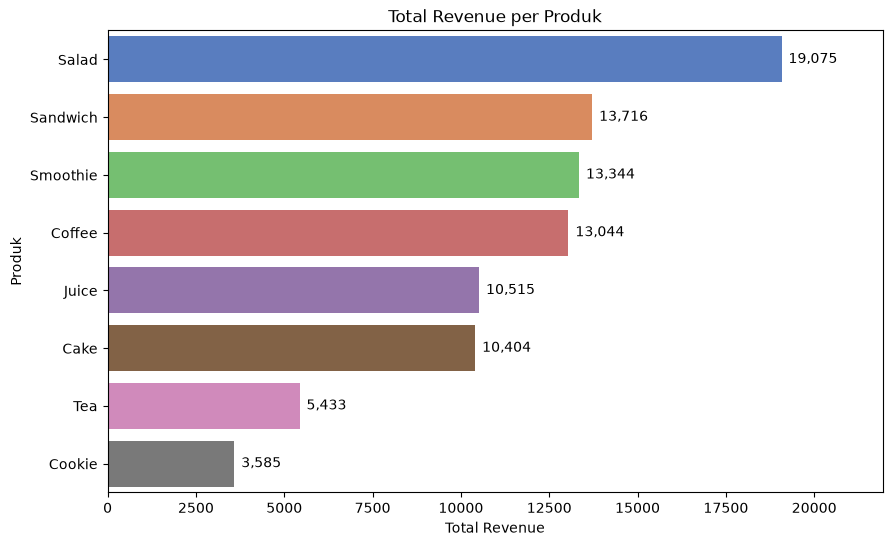

In [42]:
# Total Revenue per Produk
revenue_item = (
    df.groupby('Item')['Total_Spent']
      .sum()
      .sort_values(ascending=False)
      .reset_index()
)
revenue_item.columns = ['Item', 'Total Revenue']
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=revenue_item, 
    x='Total Revenue', 
    y='Item', 
    hue='Item',
    palette='muted', 
    legend=False,
    ax=ax
)
for container in ax.containers:
    ax.bar_label(
        container, 
        fmt='{:,.0f}',
        padding=5,
    )
ax.set_title('Total Revenue per Produk')
ax.set_xlabel('Total Revenue')
ax.set_ylabel('Produk')
ax.set_xlim(0, revenue_item['Total Revenue'].max() * 1.15)
plt.show()

**Insight**:
- Salad menjadi penyumbang pendapatan terbesar dengan $19.075,00 (21,41%), disusul Sandwich ($13.716) dan Smoothie ($13.344). Coffee berada di posisi ke-4 ($13.024), sementara Cookie ($3.585) dan Tea ($5.433) menghasilkan revenue terendah.
- Coffee adalah volume leader (paling laku), tetapi Salad & Sandwich adalah revenue driver utama karena harga satuannya lebih tinggi. Kafe sebaiknya membuat paket bundling "Coffee + Salad/Sandwich" untuk mengonversi tingginya volume kopi menjadi lonjakan pendapatan.

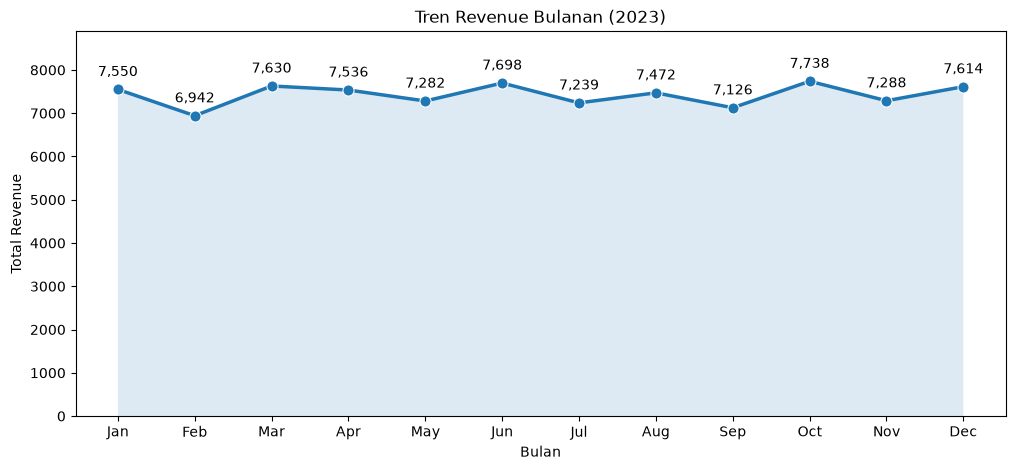

In [55]:
# Tren Revenue Bulanan
monthly_rev = (
    df.groupby('Month_Name')['Total_Spent']
      .sum()
      .reindex(month_order)
      .reset_index()
)
monthly_rev.columns = ['Bulan', 'Total Revenue']

fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(
    data=monthly_rev, 
    x='Bulan', 
    y='Total Revenue',
    marker='o', 
    linewidth=2.5, 
    markersize=8,
    ax=ax
)
ax.fill_between(
    monthly_rev['Bulan'], 
    monthly_rev['Total Revenue'],
    alpha=0.15,
)
offset = monthly_rev['Total Revenue'].max() * 0.04 
for i, row in monthly_rev.iterrows():
    ax.text(i, row['Total Revenue'] + offset, f"{row['Total Revenue']:,.0f}",
            ha='center')
ax.set_title('Tren Revenue Bulanan (2023)')
ax.set_xlabel('Bulan')
ax.set_ylabel('Total Revenue')
ax.set_ylim(0, monthly_rev['Total Revenue'].max() * 1.15)
plt.show()

**Insight:**
- Revenue bulanan bergerak stabil pada rentang $6.934,00 – $7.738,50. Titik tertinggi dicapai pada Oktober ($7.738,50) dan Juni ($7.698,00).
- cash flow kafe sangat stabil. Momentum libur panjang atau akhir tahun dapat dimanfaatkan untuk peluncuran menu musiman guna memaksimalkan profit.

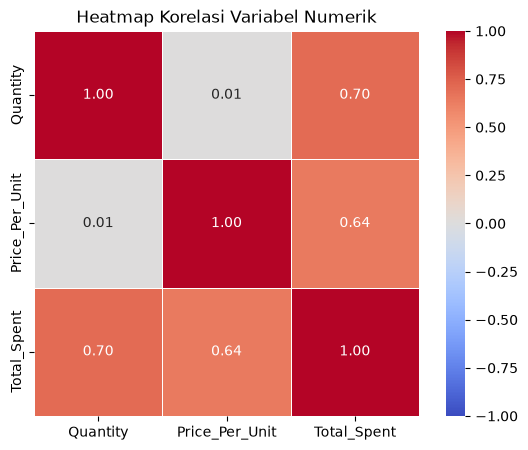

In [44]:
# Heatmap Korelasi Variabel Numerik
num_cols  = ['Quantity', 'Price_Per_Unit', 'Total_Spent']
corr_matrix = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, linewidths=0.5,
            square=True, ax=ax)
ax.set_title('Heatmap Korelasi Variabel Numerik')
plt.show()

**Insight:**
- Pelanggan kafe cenderung tetap membeli 3–5 unit baik untuk item berharga murahmaupun berharga lebih tinggi . Manajemen dapat menaikkan harga satuan produk premium secara terukur tanpa khawatir volume pembelian unit akan anjlok drastis.

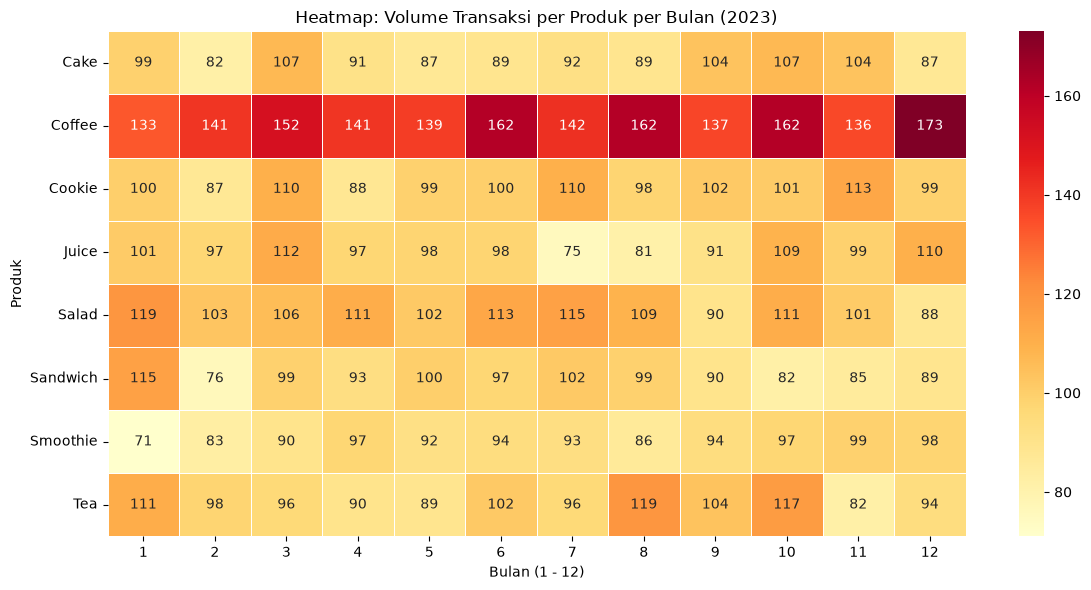

In [45]:
# Hubungan Item dan Bulan
heatmap_data = pd.crosstab(df['Item'], df['Month'])
plt.figure(figsize=(12, 6))
sns.heatmap(
    heatmap_data, 
    annot=True,     
    fmt='d',         
    cmap='YlOrRd',   
    linewidths=0.5  
)

plt.title('Heatmap: Volume Transaksi per Produk per Bulan (2023)')
plt.xlabel('Bulan (1 - 12)')
plt.ylabel('Produk')
plt.tight_layout()
plt.show()

**Insight:**
- Coffee konsisten menjadi produk terlaris di setiap bulan
- Tidak diperlukan penggantian menu musiman besar-besaran karena menu yang ada diminati stabil sepanjang tahun. Fokus utama adalah menjaga konsistensi mutu dan ketersediaan bahan baku setiap bulan.